# Exploration et Visualisation — Crimp Force Curve Dataset (Zenodo 15421197)
Ce notebook est dédié uniquement au chargement, à l'inspection de la structure et à la visualisation des courbes de force de sertissage (*Crimp Force Curves*) issues du dataset FAPS (`crimp_force_curves_dataset.pkl`).

## 1. Importation des bibliothèques et chargement du fichier `.pkl`

In [2]:
%pip install "numpy<2"

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Chemin vers le fichier téléchargé depuis Zenodo (à ajuster selon votre arborescence)
DATA_PATH = "../data/processed/crimp_force_curves_dataset.pkl"

# Chargement du DataFrame
df = pd.read_pickle(DATA_PATH)
print(f"Dataset chargé avec succès : {df.shape[0]} lignes et {df.shape[1]} colonnes.")

Dataset chargé avec succès : 2439 lignes et 11 colonnes.


## 2. Inspection de la structure et des colonnes du dataset

In [2]:
# Afficher les colonnes, les types de données et un aperçu des premières lignes
print("Colonnes disponibles :", df.columns.tolist())
print("\nInformations générales :")
df.info()

display(df.head())

Colonnes disponibles : ['CrimpID', 'Wire_cross-section_conductor', 'Force_curve_raw', 'Force_curve_baseline', 'Force_curve_RoI', 'Main_label_string', 'Main-label_encoded', 'Sub_label_string', 'Sub_label_encoded', 'Binary_label_encoded', 'CFM_label_encoded']

Informations générales :
<class 'pandas.core.frame.DataFrame'>
Index: 2439 entries, 0 to 2439
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   CrimpID                       2439 non-null   Int64  
 1   Wire_cross-section_conductor  2439 non-null   float64
 2   Force_curve_raw               2439 non-null   object 
 3   Force_curve_baseline          2439 non-null   object 
 4   Force_curve_RoI               2439 non-null   object 
 5   Main_label_string             2439 non-null   object 
 6   Main-label_encoded            2439 non-null   int64  
 7   Sub_label_string              2439 non-null   object 
 8   Sub_label_encoded  

,CrimpID,Wire_cross-section_conductor,Force_curve_raw,Force_curve_baseline,Force_curve_RoI,Main_label_string,Main-label_encoded,Sub_label_string,Sub_label_encoded,Binary_label_encoded,CFM_label_encoded
0,18016,0.5,"[18583.0, 18583.0, 18583.0, 18583.0, 18583.0, ...","[-3.0, -3.0, -3.0, -3.0, -3.0, -3.0, -3.0, -3....","[-12.0, -12.0, -12.0, -12.0, -12.0, -12.0, -11...",OK,0,OK,0,0,0
1,18017,0.5,"[18584.0, 18584.0, 18583.0, 18583.0, 18583.0, ...","[-5.0, -5.0, -4.0, -4.0, -4.0, -4.0, -4.0, -5....","[-10.0, -10.0, -9.0, -8.0, -8.0, -8.0, -8.0, -...",OK,0,OK,0,0,0
2,18018,0.5,"[18590.0, 18590.0, 18590.0, 18589.0, 18589.0, ...","[-6.0, -6.0, -6.0, -5.0, -5.0, -6.0, -6.0, -6....","[-13.0, -13.0, -13.0, -13.0, -13.0, -13.0, -12...",OK,0,OK,0,0,0
3,18019,0.5,"[18590.0, 18590.0, 18589.0, 18589.0, 18589.0, ...","[-7.0, -7.0, -6.0, -6.0, -6.0, -7.0, -7.0, -7....","[-13.0, -13.0, -13.0, -13.0, -13.0, -13.0, -12...",OK,0,OK,0,0,0
4,18020,0.5,"[18591.0, 18590.0, 18590.0, 18591.0, 18591.0, ...","[-5.0, -4.0, -4.0, -5.0, -5.0, -5.0, -5.0, -4....","[-8.0, -7.0, -7.0, -7.0, -7.0, -7.0, -7.0, -6....",OK,0,OK,0,0,0


## 3. Distribution des classes de qualité et des anomalies

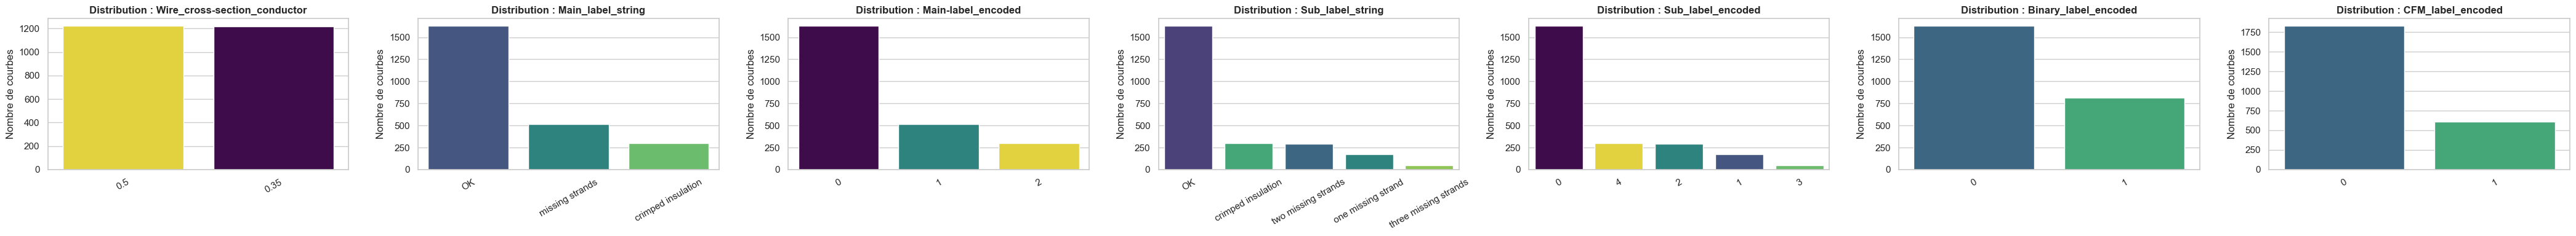

In [3]:
# Détection automatique des colonnes catégorielles / labels (hors colonne de série temporelle)
label_cols = [
    col for col in df.columns 
    if not isinstance(df[col].iloc[0], (list, np.ndarray, pd.Series)) and df[col].nunique() < 50
]

if label_cols:
    n_cols = len(label_cols)
    fig, axes = plt.subplots(1, n_cols, figsize=(6 * n_cols, 4))
    if n_cols == 1:
        axes = [axes]

    for ax, col in zip(axes, label_cols):
        order = df[col].value_counts().index
        sns.countplot(data=df, x=col, order=order, ax=ax, palette="viridis", hue=col, legend=False)
        ax.set_title(f"Distribution : {col}", fontsize=12, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Nombre de courbes")
        ax.tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()
else:
    print("Aucune colonne de label catégoriel détectée automatiquement.")

## 4. Visualisation des courbes de force de sertissage (Séries temporelles)

Colonne de courbes détectée : 'Force_curve_raw'


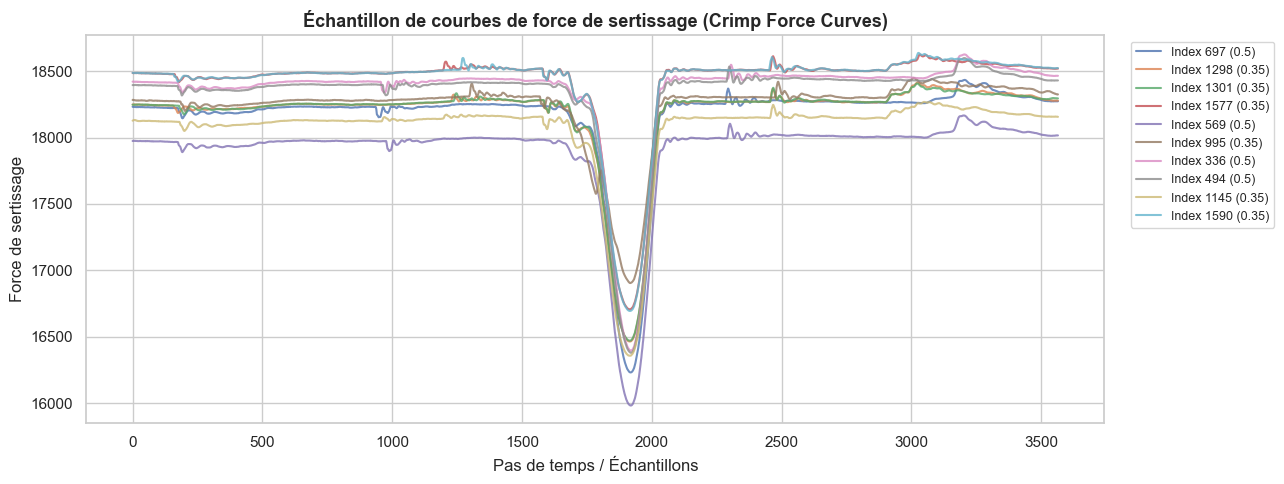

In [4]:
# Identifier automatiquement la colonne contenant les séries temporelles (tableaux/listes)
curve_col = next(
    (col for col in df.columns if isinstance(df[col].iloc[0], (list, np.ndarray, pd.Series))),
    None
)

if curve_col is None:
    # Si chaque pas de temps est une colonne numérique distincte
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    print(f"Les séries temporelles semblent réparties sur {len(num_cols)} colonnes numériques.")
    curves = df[num_cols].values
else:
    print(f"Colonne de courbes détectée : '{curve_col}'")
    curves = df[curve_col].values

# Tracer un échantillon de 10 courbes aléatoires
plt.figure(figsize=(13, 5))
sample_indices = np.random.choice(len(df), size=min(10, len(df)), replace=False)

for idx in sample_indices:
    label_str = f"Index {idx}"
    if label_cols:
        label_str += f" ({df[label_cols[0]].iloc[idx]})"
    plt.plot(curves[idx], alpha=0.8, label=label_str)

plt.title("Échantillon de courbes de force de sertissage (Crimp Force Curves)", fontsize=13, fontweight="bold")
plt.xlabel("Pas de temps / Échantillons")
plt.ylabel("Force de sertissage")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Comparaison visuelle par classe de défaut / qualité (Courbe moyenne ± écart-type)

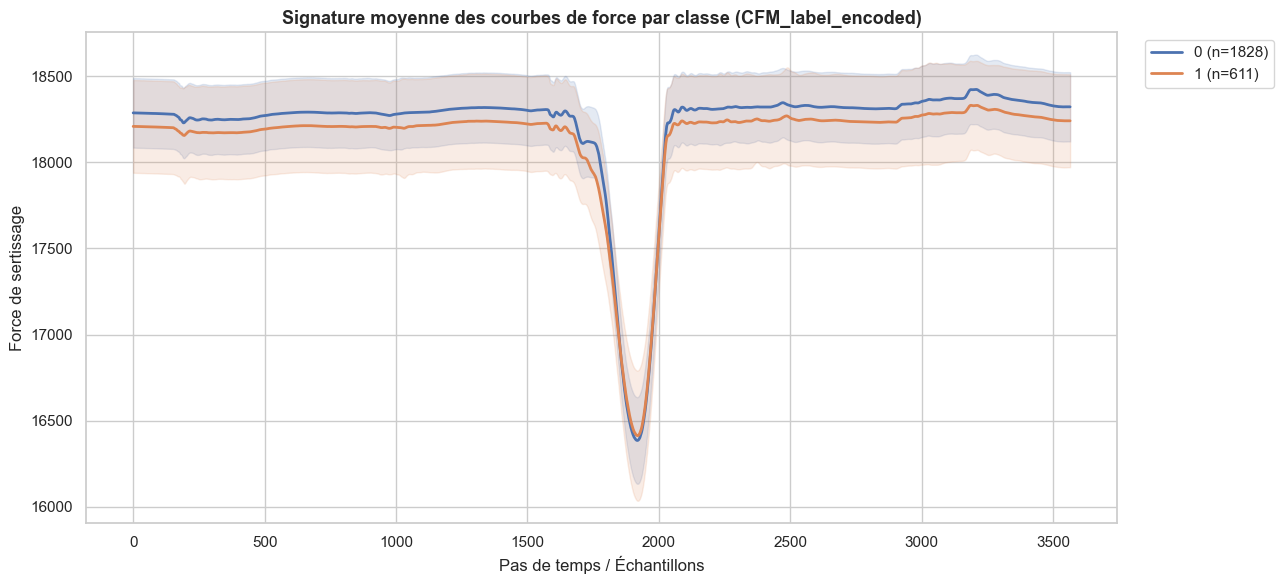

In [6]:
if label_cols:
    target_col = label_cols[-1]  # Colonne d'annotation experte
    classes = df[target_col].unique()

    plt.figure(figsize=(13, 6))
    for cls in classes:
        # Récupérer directement les sous-lignes du DataFrame pour cette classe
        subset_df = df[df[target_col] == cls]
        if len(subset_df) == 0:
            continue
            
        # Extraire les courbes correspondantes de manière sécurisée
        if isinstance(df[curve_col].iloc[0], (list, np.ndarray, pd.Series)):
            subset_curves = [np.asarray(c) for c in subset_df[curve_col]]
        else:
            subset_curves = [np.asarray(subset_df.loc[idx, num_cols]) for idx in subset_df.index]

        min_len = min(len(c) for c in subset_curves)
        aligned = np.vstack([c[:min_len] for c in subset_curves])

        mean_curve = aligned.mean(axis=0)
        std_curve = aligned.std(axis=0)

        line, = plt.plot(mean_curve, linewidth=2, label=f"{cls} (n={len(subset_curves)})")
        plt.fill_between(
            range(min_len),
            mean_curve - std_curve,
            mean_curve + std_curve,
            color=line.get_color(),
            alpha=0.15
        )

    plt.title(f"Signature moyenne des courbes de force par classe ({target_col})", fontsize=13, fontweight="bold")
    plt.xlabel("Pas de temps / Échantillons")
    plt.ylabel("Force de sertissage")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()